
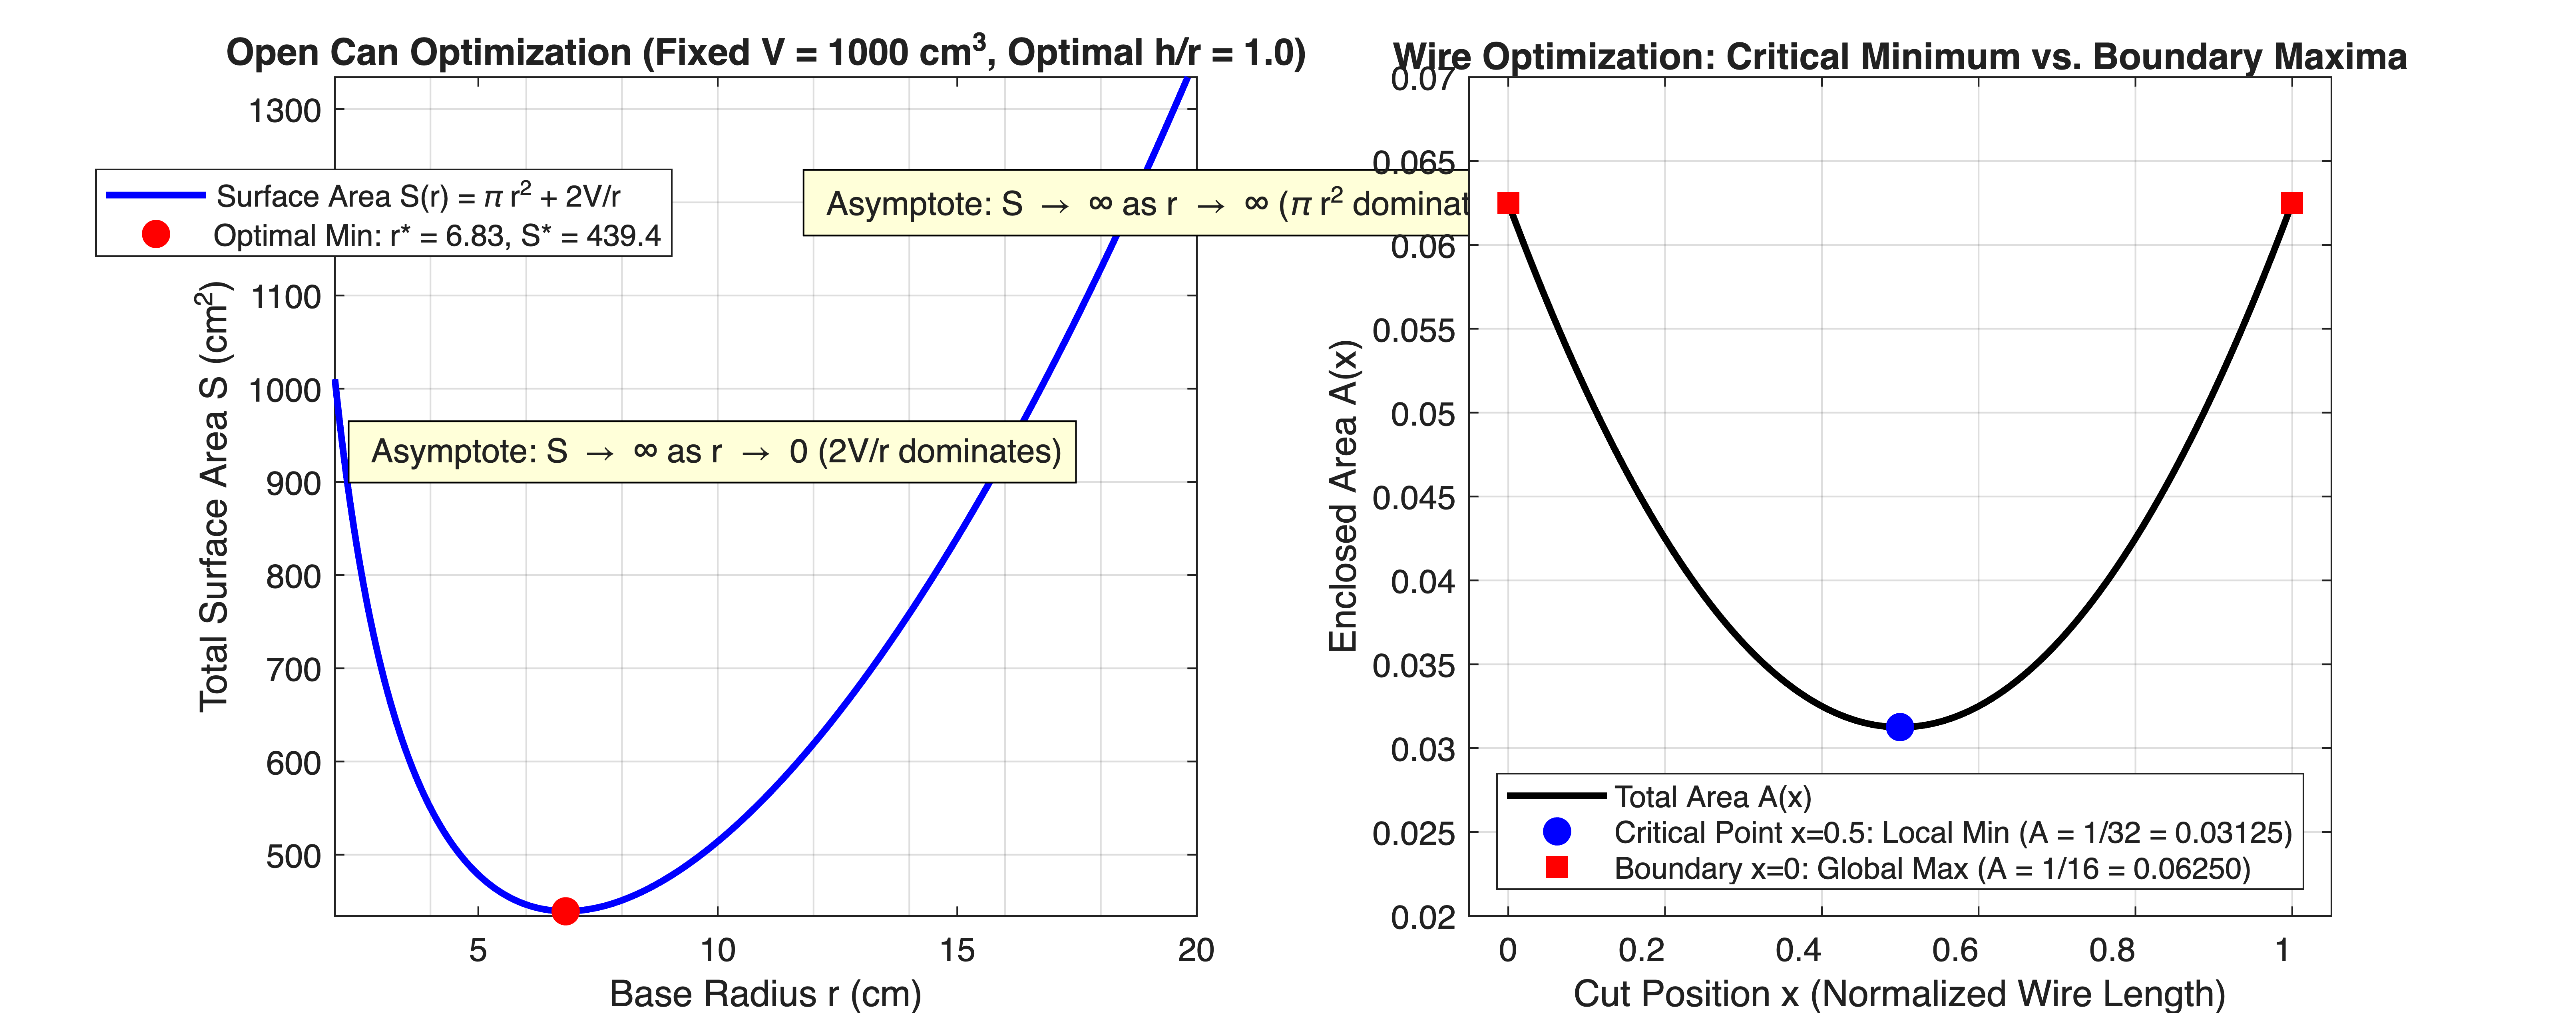

In [1]:
%% MIT 18.01 Lecture 11: Max/Min Problems & Boundary Optimization
% Mathematical Tool Application: Solves static parameter optimization,
% analyzes constraint elimination, and evaluates boundary-dominant optima
% corresponding to actuator saturation limits in control systems.


clear; clc; close all;


%% Part 1: Constrained Can Surface Area Minimization (Example 3)
% Target fixed volume V = 1000 cm^3 (1 Liter)
V_fixed = 1000.0;


% Theoretical optimal dimensions: r* = (V/pi)^(1/3), h* = r*
r_opt = (V_fixed / pi)^(1/3);
h_opt = V_fixed / (pi * r_opt^2);
S_min = pi * r_opt^2 + 2 * V_fixed / r_opt; % S = 3 * pi^(2/3) * (V/pi)^(2/3)


% Radius domain (avoiding division by zero at r = 0)
r_span = linspace(2.0, 20.0, 400);
S_span = pi * r_span.^2 + 2 * V_fixed ./ r_span;


figure('Color', 'w', 'Position', [100, 100, 1200, 480]);


subplot(1, 2, 1);
plot(r_span, S_span, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Surface Area S(r) = \pi r^2 + 2V/r'); hold on;
plot(r_opt, S_min, 'ro', 'MarkerSize', 8, 'MarkerFaceColor', 'r', ...
    'DisplayName', sprintf('Optimal Min: r* = %.2f, S* = %.1f', r_opt, S_min));


% Annotate asymptotic boundary behaviors
text(2.5, S_span(5), ' Asymptote: S \rightarrow \infty as r \rightarrow 0 (2V/r dominates)', ...
    'BackgroundColor', [1 1 0.85], 'EdgeColor', 'k');
text(12.0, S_span(end-30), ' Asymptote: S \rightarrow \infty as r \rightarrow \infty (\pi r^2 dominates)', ...
    'BackgroundColor', [1 1 0.85], 'EdgeColor', 'k');


grid on;
xlim([2, 20]); ylim([300, 1200]);
xlabel('Base Radius r (cm)');
ylabel('Total Surface Area S (cm^2)');
title(sprintf('Open Can Optimization (Fixed V = %.0f cm^3, Optimal h/r = %.1f)', V_fixed, h_opt/r_opt));
legend('Location', 'northeast');


%% Part 2: Wire Cutting Area Optimization (Example 4)
% Total length L = 1.0. Cut coordinate x in [0, 1].
% Area A(x) = (x/4)^2 + ((1-x)/4)^2
x_span = linspace(0, 1.0, 300);
A_span = (x_span / 4).^2 + ((1 - x_span) / 4).^2;


x_crit = 0.5;
A_min = (x_crit / 4)^2 + ((1 - x_crit) / 4)^2; % 1/32 = 0.03125
A_max = (1.0 / 4)^2;                          % 1/16 = 0.06250 (at x=0 or x=1)


subplot(1, 2, 2);
plot(x_span, A_span, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Total Area A(x)'); hold on;


% Critical point is a local minimum
plot(x_crit, A_min, 'bo', 'MarkerSize', 8, 'MarkerFaceColor', 'b', ...
    'DisplayName', sprintf('Critical Point x=0.5: Local Min (A = 1/32 = %.5f)', A_min));


% Boundary endpoints are global maxima
plot(0, A_max, 'rs', 'MarkerSize', 8, 'MarkerFaceColor', 'r', ...
    'DisplayName', sprintf('Boundary x=0: Global Max (A = 1/16 = %.5f)', A_max));
plot(1, A_max, 'rs', 'MarkerSize', 8, 'MarkerFaceColor', 'r', 'HandleVisibility', 'off');


grid on;
xlim([-0.05, 1.05]); ylim([0.02, 0.07]);
xlabel('Cut Position x (Normalized Wire Length)');
ylabel('Enclosed Area A(x)');
title('Wire Optimization: Critical Minimum vs. Boundary Maxima');
legend('Location', 'south');